# Project 2: MLP from Scratch (NumPy)
Forward pass, backpropagation and mini-batch SGD written with **NumPy only**, trained on MNIST,
validated with **numerical gradient checking**, and compared against **PyTorch**.

Run the cells top to bottom (Runtime > Run all).

## Step 1: Load MNIST

(60000, 784) (60000,) (10000, 784) (10000,)


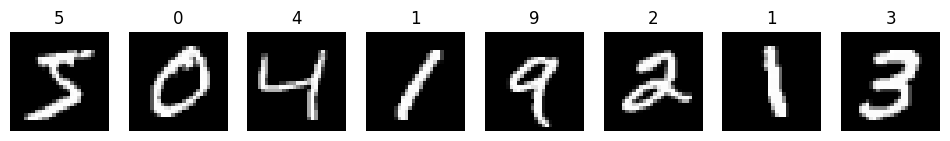

In [7]:
import numpy as np, matplotlib.pyplot as plt, time
import torch, torch.nn as nn
from torchvision import datasets

tr = datasets.MNIST('./data', train=True, download=True)
te = datasets.MNIST('./data', train=False, download=True)

def prep(ds):
    X = ds.data.numpy().reshape(-1, 784).astype(np.float32) / 255.0
    X = (X - 0.1307) / 0.3081          # standard MNIST normalisation
    return X, ds.targets.numpy().astype(np.int64)

Xtr, ytr = prep(tr)
Xte, yte = prep(te)
print(Xtr.shape, ytr.shape, Xte.shape, yte.shape)

fig, ax = plt.subplots(1, 8, figsize=(12, 2))
for i, a in enumerate(ax):
    a.imshow(Xtr[i].reshape(28, 28), cmap='gray'); a.set_title(int(ytr[i])); a.axis('off')
plt.show()

## Step 2: Build the network (layers, loss)
Each layer stores what it needs in `forward` and uses it in `backward`.

- Dense: `y = xW + b`, so `dW = x^T dy`, `db = sum(dy)`, `dx = dy W^T`
- ReLU: `dx = dy * (x > 0)`
- Softmax + cross-entropy combined: gradient w.r.t. logits is `(softmax - onehot) / N`

In [8]:
class Dense:
    def __init__(self, n_in, n_out, rng, dtype=np.float32):
        # He initialisation (good for ReLU)
        self.W = (rng.standard_normal((n_in, n_out)) * np.sqrt(2.0 / n_in)).astype(dtype)
        self.b = np.zeros(n_out, dtype=dtype)
    def forward(self, x):
        self.x = x
        return x @ self.W + self.b
    def backward(self, dout):
        self.dW = self.x.T @ dout
        self.db = dout.sum(axis=0)
        return dout @ self.W.T

class ReLU:
    def forward(self, x):
        self.mask = x > 0
        return x * self.mask
    def backward(self, dout):
        return dout * self.mask

def softmax_cross_entropy(logits, y):
    z = logits - logits.max(axis=1, keepdims=True)          # numerical stability
    logp = z - np.log(np.exp(z).sum(axis=1, keepdims=True))
    N = len(y)
    loss = -logp[np.arange(N), y].mean()
    grad = np.exp(logp)
    grad[np.arange(N), y] -= 1
    return loss, grad / N

class MLP:
    def __init__(self, sizes, seed=0, dtype=np.float32):
        rng = np.random.default_rng(seed)
        self.layers = []
        for i in range(len(sizes) - 1):
            self.layers.append(Dense(sizes[i], sizes[i + 1], rng, dtype))
            if i < len(sizes) - 2:
                self.layers.append(ReLU())
    def forward(self, x):
        for l in self.layers: x = l.forward(x)
        return x
    def backward(self, d):
        for l in reversed(self.layers): d = l.backward(d)
    @property
    def dense(self):
        return [l for l in self.layers if isinstance(l, Dense)]
    def step(self, lr):                                      # plain SGD update
        for l in self.dense:
            l.W -= lr * l.dW
            l.b -= lr * l.db

## Step 3: Gradient checking (proves backprop is correct)
Compare analytic gradients to centred finite differences `(L(w+e) - L(w-e)) / 2e` in float64.

In [9]:
def grad_check(sizes=(20, 15, 10, 5), eps=1e-6, n_checks=10, seed=1):
    rng = np.random.default_rng(seed)
    model = MLP(list(sizes), seed=seed, dtype=np.float64)
    X = rng.standard_normal((8, sizes[0])); y = rng.integers(0, sizes[-1], 8)
    loss, d = softmax_cross_entropy(model.forward(X), y)
    model.backward(d)
    worst = 0
    for li, l in enumerate(model.dense):
        for name in ('W', 'b'):
            p, g = getattr(l, name), getattr(l, 'd' + name)
            for _ in range(n_checks):
                idx = tuple(rng.integers(0, s) for s in p.shape)
                orig = p[idx]
                p[idx] = orig + eps; lp, _ = softmax_cross_entropy(model.forward(X), y)
                p[idx] = orig - eps; lm, _ = softmax_cross_entropy(model.forward(X), y)
                p[idx] = orig
                num = (lp - lm) / (2 * eps)
                rel = abs(num - g[idx]) / max(abs(num) + abs(g[idx]), 1e-12)
                worst = max(worst, rel)
    print(f"max relative error = {worst:.2e}  ->", "PASS" if worst < 1e-6 else "CHECK YOUR BACKWARD PASS")

grad_check()

max relative error = 1.41e-08  -> PASS


## Step 4: Train on MNIST with mini-batch SGD

In [10]:
def evaluate(model, X, y, bs=2000):
    correct, loss = 0, 0.0
    for i in range(0, len(X), bs):
        out = model.forward(X[i:i + bs])
        l, _ = softmax_cross_entropy(out, y[i:i + bs])
        loss += l * len(out)
        correct += (out.argmax(1) == y[i:i + bs]).sum()
    return loss / len(X), correct / len(X)

def train(model, epochs=15, lr=0.1, bs=128, seed=0):
    rng = np.random.default_rng(seed)
    hist = {'train_loss': [], 'test_loss': [], 'test_acc': []}
    for ep in range(1, epochs + 1):
        perm = rng.permutation(len(Xtr))
        run, nb = 0.0, 0
        for i in range(0, len(Xtr), bs):
            idx = perm[i:i + bs]
            loss, d = softmax_cross_entropy(model.forward(Xtr[idx]), ytr[idx])
            model.backward(d)
            model.step(lr)
            run += loss; nb += 1
        tl, ta = evaluate(model, Xte, yte)
        hist['train_loss'].append(run / nb); hist['test_loss'].append(tl); hist['test_acc'].append(ta)
        print(f"epoch {ep:2d} | train loss {run/nb:.4f} | test loss {tl:.4f} | test acc {ta*100:.2f}%")
    return hist

t0 = time.time()
model = MLP([784, 256, 128, 10], seed=0)
hist = train(model, epochs=15, lr=0.1, bs=128)
print(f"NumPy MLP: {hist['test_acc'][-1]*100:.2f}% test accuracy in {time.time()-t0:.0f}s")

epoch  1 | train loss 0.2521 | test loss 0.1315 | test acc 96.05%
epoch  2 | train loss 0.1083 | test loss 0.1158 | test acc 96.51%
epoch  3 | train loss 0.0737 | test loss 0.0835 | test acc 97.39%
epoch  4 | train loss 0.0537 | test loss 0.0794 | test acc 97.34%
epoch  5 | train loss 0.0409 | test loss 0.0700 | test acc 97.81%
epoch  6 | train loss 0.0307 | test loss 0.0755 | test acc 97.67%
epoch  7 | train loss 0.0228 | test loss 0.0712 | test acc 97.69%
epoch  8 | train loss 0.0172 | test loss 0.0689 | test acc 97.87%
epoch  9 | train loss 0.0130 | test loss 0.0718 | test acc 97.88%
epoch 10 | train loss 0.0094 | test loss 0.0693 | test acc 97.93%
epoch 11 | train loss 0.0071 | test loss 0.0718 | test acc 97.94%
epoch 12 | train loss 0.0055 | test loss 0.0716 | test acc 98.02%
epoch 13 | train loss 0.0045 | test loss 0.0722 | test acc 97.94%
epoch 14 | train loss 0.0036 | test loss 0.0720 | test acc 98.06%
epoch 15 | train loss 0.0029 | test loss 0.0725 | test acc 98.03%
NumPy MLP:

## Step 5: Plots and error analysis

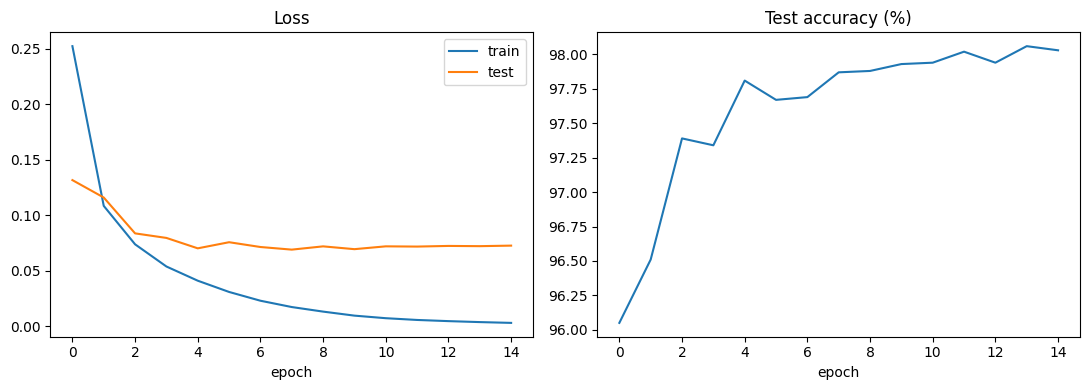

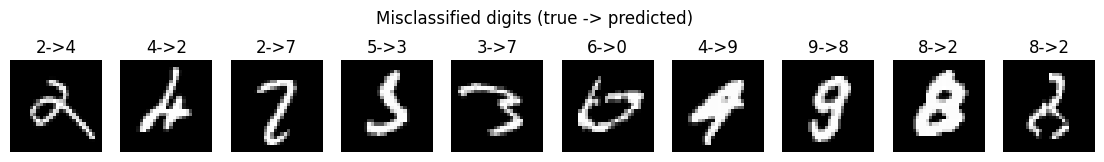

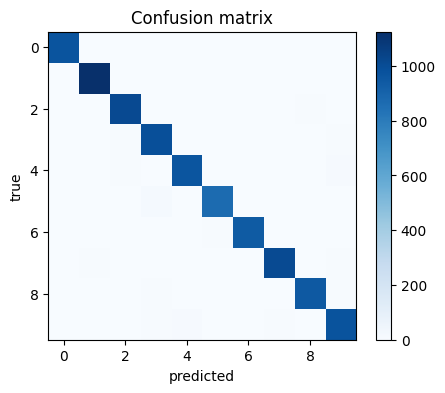

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(hist['train_loss'], label='train'); ax[0].plot(hist['test_loss'], label='test')
ax[0].set_title('Loss'); ax[0].set_xlabel('epoch'); ax[0].legend()
ax[1].plot(np.array(hist['test_acc']) * 100); ax[1].set_title('Test accuracy (%)'); ax[1].set_xlabel('epoch')
plt.tight_layout(); plt.show()

pred = np.concatenate([model.forward(Xte[i:i+2000]).argmax(1) for i in range(0, len(Xte), 2000)])
wrong = np.where(pred != yte)[0][:10]
fig, ax = plt.subplots(1, 10, figsize=(14, 2))
for a, i in zip(ax, wrong):
    a.imshow(Xte[i].reshape(28, 28), cmap='gray'); a.set_title(f"{yte[i]}->{pred[i]}"); a.axis('off')
plt.suptitle('Misclassified digits (true -> predicted)'); plt.show()

cm = np.zeros((10, 10), int)
for t, p in zip(yte, pred): cm[t, p] += 1
plt.figure(figsize=(5, 4)); plt.imshow(cm, cmap='Blues'); plt.colorbar()
plt.title('Confusion matrix'); plt.xlabel('predicted'); plt.ylabel('true'); plt.show()

## Step 6: PyTorch comparison
1. **Gradient match**: copy the same weights into PyTorch and compare gradients on one batch.
2. **Training match**: train the same architecture with PyTorch SGD and compare accuracy.

In [12]:
# --- 6a: gradient match (float64) ---
sizes = [20, 15, 10, 5]
m = MLP(sizes, seed=3, dtype=np.float64)
rng = np.random.default_rng(3)
X = rng.standard_normal((16, 20)); y = rng.integers(0, 5, 16)
loss, d = softmax_cross_entropy(m.forward(X), y); m.backward(d)

tm = nn.Sequential(nn.Linear(20, 15), nn.ReLU(), nn.Linear(15, 10), nn.ReLU(), nn.Linear(10, 5)).double()
lins = [l for l in tm if isinstance(l, nn.Linear)]
with torch.no_grad():
    for tl_, l in zip(lins, m.dense):
        tl_.weight.copy_(torch.from_numpy(l.W.T)); tl_.bias.copy_(torch.from_numpy(l.b))
tl = nn.functional.cross_entropy(tm(torch.from_numpy(X)), torch.from_numpy(y)); tl.backward()

maxdiff = 0
for tl_, l in zip(lins, m.dense):
    maxdiff = max(maxdiff, np.abs(tl_.weight.grad.numpy().T - l.dW).max(), np.abs(tl_.bias.grad.numpy() - l.db).max())
print(f"loss: numpy {loss:.8f} vs torch {tl.item():.8f}")
print(f"max |grad_numpy - grad_torch| = {maxdiff:.2e}")

# --- 6b: training comparison ---
torch.manual_seed(0)
dev = 'cuda' if torch.cuda.is_available() else 'cpu'
net = nn.Sequential(nn.Linear(784, 256), nn.ReLU(), nn.Linear(256, 128), nn.ReLU(), nn.Linear(128, 10)).to(dev)
opt = torch.optim.SGD(net.parameters(), lr=0.1)
Xt, yt = torch.from_numpy(Xtr).to(dev), torch.from_numpy(ytr).to(dev)
Xe, ye = torch.from_numpy(Xte).to(dev), torch.from_numpy(yte).to(dev)
t0 = time.time()
for ep in range(15):
    perm = torch.randperm(len(Xt), device=dev)
    for i in range(0, len(Xt), 128):
        idx = perm[i:i + 128]
        opt.zero_grad(); nn.functional.cross_entropy(net(Xt[idx]), yt[idx]).backward(); opt.step()
with torch.no_grad():
    acc = (net(Xe).argmax(1) == ye).float().mean().item()
print(f"PyTorch MLP: {acc*100:.2f}% test accuracy in {time.time()-t0:.0f}s on {dev}")
print(f"NumPy  MLP: {hist['test_acc'][-1]*100:.2f}%")

loss: numpy 1.76275049 vs torch 1.76275049
max |grad_numpy - grad_torch| = 5.55e-17
PyTorch MLP: 98.31% test accuracy in 25s on cpu
NumPy  MLP: 98.03%


## Step 7: What to write down for your resume / README
- Final NumPy test accuracy and PyTorch test accuracy (from the cells above)
- Gradient-check max relative error and NumPy-vs-PyTorch max gradient difference
- Architecture (784-256-128-10), optimizer (mini-batch SGD, lr 0.1, batch 128), epochs

Optional extensions: add momentum or Adam, L2 regularisation, dropout, learning-rate decay, or try different widths/depths.